# Project B: Molecular property prediction with graph neural networks (QM9)

###  Motivation

QM9 molecules are graphs, not vectors: atoms have no natural order, and a molecule's properties don't depend on how it's oriented in space. Here, we build that physics directly into the GNN model (rather than hoping a network learns it from data) by:
1. using interatomic distances (and not raw coordinates) as edge (rotation/translation invariance).
2. Permutation-invariant aggregation pooling so atom ordering can't affect the prediction. 

 **Structure matters yet order does not**

The point of using a GNN specifically (rather than a plain neural network that just takes a flat list of numbers) is that a molecule's structure genuinely matters for its properties. For example, two molecules with the same atoms connected differently can have very different HOMO-LUMO gaps. A GNN can "see" that structure directly: it looks at each atom, looks at what it's bonded to, and passes information along those bonds so each atom's understanding of "what molecule am I part of" gets built up from its actual neighbors and how far apart they are.

However, the labeling of that structure does not matter. If we take a molecule and just relabel which atom is "atom 0" vs "atom 1" *without changing any bonds or distances* - it's still the same molecule. The structure is identical - only the arbitrary positions in a list have changed. The prediction shouldn't change, because nothing physical changed.

So GNN is sensitive to structure (bonds, distances - that's what all the message-passing machinery is for) while being completely insensitive to the arbitrary labeling of that structure (that's what sum-aggregation and pooling guarantee).

Comparing a message-passing GNN against a set-transformer tests whether explicit bond structure is **actually needed**, or whether distance-biased attention over an **unordered atom set** can match it. 

Since a predictor is only useful if you know when to trust it, both models also need calibrated uncertainty which flags molecules that are far from the training distribution.   

### Getting the data for Project B

The **real QM9** dataset.

In [1]:
import torch

# ---- load the REAL QM9 (downloads on first call) ----
from torch_geometric.datasets import QM9

dataset = QM9(root="data/QM9")            # each item: .z (atom types), .pos (3D), .edge_index, .y (19 targets)
print(dataset[0]); target_index = 4       # e.g. HOMO-LUMO gap; see QM9 docs for the column meanings

# Build edge_index from geometry if you prefer a radius graph: torch_geometric.nn.radius_graph(pos, r=...)
print("MolGNN ready. Uncomment the QM9 loader to download the real molecules.")

c:\Users\eden1\anaconda3\envs\dl_course\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Data(x=[5, 11], edge_index=[2, 8], edge_attr=[8, 4], y=[1, 19], pos=[5, 3], idx=[1], name='gdb_1', z=[5])
MolGNN ready. Uncomment the QM9 loader to download the real molecules.


In [2]:
# using the first molecule's graph as an example

# accessing the first molecule in the dataset
molecule_0 = dataset[0]

# printing all available keys/attributes of this first molecule's graph object
print("All available keys are:", molecule_0.keys())

# accessing the target properties tensor (shape: [1, 19]) of the first molecule
properties = molecule_0.y
print("Properties tensor:", properties)

# extracting a specific property (e.g., Dipole moment which is at index 0)
dipole_moment = properties[0][0].item()
print("Dipole moment (mu):", dipole_moment)

# access atomic numbers for each node (atom) in the first molecule's graph
atomic_numbers = molecule_0.z
print("Atomic numbers:", atomic_numbers)

mol = dataset[0]
print(type(mol.z))   # <class 'torch.Tensor'>
print(type(mol.pos)) # <class 'torch.Tensor'>

All available keys are: ['x', 'y', 'name', 'edge_attr', 'z', 'idx', 'pos', 'edge_index']
Properties tensor: tensor([[    0.0000,    13.2100,   -10.5499,     3.1865,    13.7363,    35.3641,
             1.2177, -1101.4878, -1101.4098, -1101.3840, -1102.0229,     6.4690,
           -17.1722,   -17.2868,   -17.3897,   -16.1519,   157.7118,   157.7100,
           157.7070]])
Dipole moment (mu): 0.0
Atomic numbers: tensor([6, 1, 1, 1, 1])
<class 'torch.Tensor'>
<class 'torch.Tensor'>



**The 19 target properties (`.y`, one row per molecule, columns 0–18):**

| idx | property | unit | extensive/intensive |
|---|---|---|---|
| 0 | dipole moment (μ) | Debye | intensive |
| 1 | isotropic polarizability (α) | Bohr³ | extensive-ish |
| 2 | HOMO energy | eV | intensive |
| 3 | LUMO energy | eV | intensive |
| 4 | HOMO–LUMO gap | eV | intensive |
| 5 | electronic spatial extent (⟨R²⟩) | Bohr² | extensive |
| 6 | zero-point vibrational energy (ZPVE) | eV | extensive |
| 7 | internal energy at 0K (U0) | eV | extensive |
| 8 | internal energy at 298K (U) | eV | extensive |
| 9 | enthalpy at 298K (H) | eV | extensive |
| 10 | free energy at 298K (G) | eV | extensive |
| 11 | heat capacity at 298K (Cv) | cal/(mol·K) | extensive |
| 12 | atomization energy at 0K | eV | extensive |
| 13 | atomization energy at 298K | eV | extensive |
| 14 | atomization enthalpy at 298K | eV | extensive |
| 15 | atomization free energy at 298K | eV | extensive |
| 16 | rotational constant A | GHz | intensive |
| 17 | rotational constant B | GHz | intensive |
| 18 | rotational constant C | GHz | intensive |


The target property I chose to predict is the **HOMO LUMO gap**. 

The HOMO–LUMO gap describes how "reactive" or "stable" a molecule's electrons are.
In a molecule, electrons sit in specific energy levels. The HOMO (Highest Occupied Molecular Orbital) is the highest-energy orbital that actually has an electron in it. The LUMO (Lowest Unoccupied Molecular Orbital) is the lowest-energy orbital that's empty. 

The gap between them is: LUMO energy minus HOMO energy. It's measured in eV and indicates roughly how much energy it takes to excite an electron from an occupied state to an empty one.

Physically, a large gap means the molecule is more chemically stable and less reactive (it takes a lot of energy to excite the electron) and a small gap means the molecule is more reactive/unstable.

This quantum quantity is relevant to semiconductors, solar cell materials, dyes industry and drug discovery as the HOMO-LUMO gap roughly predicts the color of light a molecule absorbs and how easily it participates in chemical reactions.

It's a good target for the GNN as it depends heavily on a molecule's structure, making the comparison of the GNN and the set transformer a meaningful test of *whether the GNN has actually learned something* about molecular geometry and bonding rather than just counting atoms.

### Train / validation / test split and preprocessing

70% (train) / 15% (validation) / 15% (testing) split.

Train (70%) - the data the model's weights actually learn from.

Validation (15%) - held out from training, tune hyperparameters, decide when to stop training.

Test (15%) - report final MAE, coverage, and calibration numbers honestly.

In [3]:
from torch_geometric.loader import DataLoader

# important: QM9 isn't stored in random order
dataset = dataset.shuffle()   

# the data loaded is already a tensor so we don't need to convert it into that
n = len(dataset)
n_train = int(0.7 * n)
n_val   = int(0.15 * n)

train_set = dataset[:n_train]
val_set   = dataset[n_train:n_train+n_val]
test_set  = dataset[n_train+n_val:]

train_loader = DataLoader(train_set, batch_size=256, shuffle=True)
val_loader = DataLoader(val_set, batch_size=256, shuffle=False)

print(f"Number of molecules in training set: {len(train_set)}\n"
      f"Number of molecules in validation set: {len(val_set)}\n"
      f"Number of molecules in test set: {len(test_set)}")

Number of molecules in training set: 91581
Number of molecules in validation set: 19624
Number of molecules in test set: 19626


---
## Model 1 - Baseline model

We will use a non-graph baseline, to predict the HOMO–LUMO gap using only each molecule's atom-type counts. For example, a molecule with 4 carbons, 8 hydrogens, and 1 oxygen would be represented as the vector [C:4, H:8, O:1, N:0, F:0] - number of H, C, N, O, and F atoms. This type of baseline model completely **discards bond connectivity and 3D geometry**, thus allowing a true comparison to a model which factors in structure.

Generally, molecule size and it's composition do correlate somewhat with many properties (more atoms, bigger molecules, different orbital structure on average). So a baseline like this isn't an easy target due to that correlation. 

The real test is: does the GNN, which can see structure, meaningfully beat this baseline? If it barely so, that's evidence the GNN isn't actually learning much from bonds/geometry - it'd just be an expensive way of counting atoms. If it clearly beats it, that's evidence the graph structure is adding real value.

In [5]:
import torch
import torch.nn as nn

target_index = 4
ATOM_TYPES = [1, 6, 7, 8, 9]  # H, C, N, O, F - the only elements present in QM9

# the function that turns a batch of molecules into the baseline's actual input (just composition)
def atom_count_features(batch):
    num_molecules = batch.num_graphs # how many original molecules got merged into this combined graph (normally 128 unless it's the last batch, then less)
    counts = torch.zeros(num_molecules, len(ATOM_TYPES), device=batch.z.device) # an empty output table: one row per molecule, one column per element.
    for i, atomic_num in enumerate(ATOM_TYPES):
        mask = (batch.z == atomic_num).float() # 1 where atom is this type, else 0
        counts[:, i] = torch.zeros(num_molecules, device=batch.z.device).index_add_(0, batch.batch, mask)
    return counts # (no. rows = num_molecules, 5) tensor
# for example: 
# row in tensor([1, 5, 7, 3, 2])
#                H  C  N  O  F

# creating the input batch and feeding it to the model, yielding predictions of the batch
def baseline_predict_fn(model, batch):
    counts = atom_count_features(batch) # build the input
    return model(counts) # insert the un-graphed input to the model which delivers the predictions

# A features-only baseline: a plain MLP that never sees the graph.
class MLPBaseline(nn.Module):
    def __init__(self, n_atom_types=5, hidden=16): # QM9 has 5 tom types
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_atom_types, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 1) # regression -> one output to predict the gap
        )
    def forward(self, counts):
        return self.net(counts).squeeze(-1) ##### squeeze


The count tensor looks like this:

| molecule | H | C | N | O | F |
|---|---|---|---|---|---|
| molecule_0 (real) | 4 | 5 | 2 | 1 | 0 |
| methane-like | 4 | 1 | 0 | 0 | 0 |
| ethanol-like | 6 | 2 | 0 | 1 | 0 |
| formaldehyde-like | 2 | 1 | 0 | 1 | 0 |
| fluoromethane-like | 3 | 1 | 0 | 0 | 1 |


We will first compose a general training function which will fit to all future models we will train.

In [4]:
# training - one training function that works for all three models - each epoch has 128 batches
def train_and_eval(model, train_loader, val_loader, predict_fn, target_index, name, epochs=10, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss() # MAE 
    history = {"train_mae": [], "val_mae": []}

    for epoch in range(epochs):
        model.train()
        total_train_error, n_train = 0.0, 0
        for batch in train_loader: # 128 batches for each epoch
            optimizer.zero_grad()
            target = batch.y[:, target_index] # pick one property column of a 19-column tensor
            pred = predict_fn(model, batch) # MAE for one single batch
            loss = loss_fn(pred, target)
            loss.backward()
            optimizer.step()
            # computing mae of entire epoch to prevent overconfidence
            # to get the true overall mean across the entire validation set, we sum up total absolute error and total molecule count across every batch, *then* divide once at the end. not all batches are the same size, thus we can't average the averages
            total_train_error += torch.sum(torch.abs(pred - target)).item() # raw sum of |error| for *this* batch, NOT averaged
            n_train += target.size(0) # how many molecules were actually in this batch
        train_mae = total_train_error / n_train # true average over all training molecules of *this* epoch

        # Validation runs once per epoch to prevent overfitting (train MAE dropping while val MAE stalls or rises) as it happens
        model.eval()
        total_val_error, n_val = 0.0, 0
        with torch.no_grad():
            for batch in val_loader:
                target = batch.y[:, target_index]
                pred = predict_fn(model, batch)
                total_val_error += torch.sum(torch.abs(pred - target)).item()
                n_val += target.size(0)
        val_mae = total_val_error / n_val

        history["train_mae"].append(train_mae)
        history["val_mae"].append(val_mae)
        print(f"epoch {epoch+1:3d} | train MAE: {train_mae:.4f} | val MAE: {val_mae:.4f} eV")

    print(f"\n{name:28s} final val MAE: {history['val_mae'][-1]:.4f} eV")
    return history

Training the baseline model.

In [75]:
base_model = MLPBaseline()
baseline_history = train_and_eval(base_model, train_loader, val_loader,
                               predict_fn=baseline_predict_fn,
                               target_index=target_index,
                               name="MLP baseline (atom counts only)")

final_baseline_mae = baseline_history["val_mae"][-1]

epoch   1 | train MAE: 1.5437 | val MAE: 0.8815 eV
epoch   2 | train MAE: 0.8725 | val MAE: 0.8756 eV
epoch   3 | train MAE: 0.8692 | val MAE: 0.8770 eV
epoch   4 | train MAE: 0.8668 | val MAE: 0.8703 eV
epoch   5 | train MAE: 0.8627 | val MAE: 0.8653 eV
epoch   6 | train MAE: 0.8577 | val MAE: 0.8590 eV
epoch   7 | train MAE: 0.8522 | val MAE: 0.8609 eV
epoch   8 | train MAE: 0.8457 | val MAE: 0.8472 eV
epoch   9 | train MAE: 0.8406 | val MAE: 0.8408 eV
epoch  10 | train MAE: 0.8356 | val MAE: 0.8385 eV

MLP baseline (atom counts only) final val MAE: 0.8385 eV


In [76]:
torch.save(base_model.state_dict(), "baseline_model.pt")

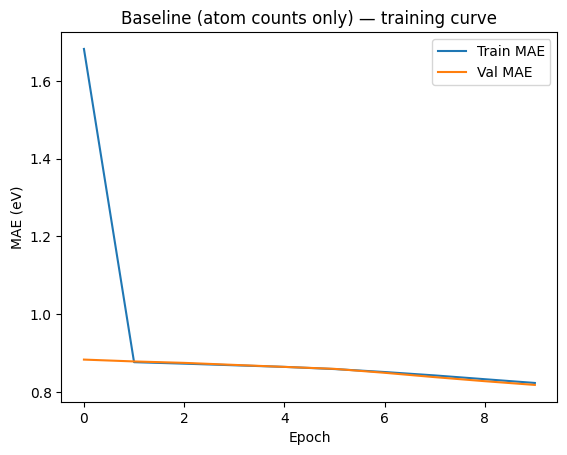

In [ ]:
import matplotlib.pyplot as plt

plt.plot(baseline_history["train_mae"], label="Train MAE")
plt.plot(baseline_history["val_mae"], label="Val MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (eV)")
plt.title("Baseline (atom counts only) - training curve")
plt.legend()
plt.show()

**Baseline training results.** With `lr=1e-2`, validation MAE fluctuated noisily rather than converging smoothly, so we lowered it to `lr=1e-3`. This produced a smooth, monotonic decrease in both train and validation MAE.

Both runs converge to essentially the same final MAE ($\approx0.83$ eV), confirming the earlier noise was an optimization artifact rather than a modeling problem, which we improved with fine tuning.

### Test set MAE

In [15]:
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)

In [78]:
def evaluate_test_mae(model, test_loader, predict_fn, target_index):
    """Final, one-time evaluation on the test set. Returns MAE in the property's physical units."""
    model.eval()
    total_error, n = 0.0, 0
    with torch.no_grad():
        for batch in test_loader:
            target = batch.y[:, target_index]
            pred = predict_fn(model, batch)
            total_error += torch.sum(torch.abs(pred - target)).item()
            n += target.size(0)
    return total_error / n

In [84]:
baseline_test_mae = evaluate_test_mae(base_model, test_loader, baseline_predict_fn, target_index)
print(f"Baseline test MAE: {baseline_test_mae:.4f} eV")

Baseline test MAE: 0.8390 eV


---
## Model 2 - Molecular GNN

A message-passing layer: 
- The message is a small network of the two atoms' features and their **interatomic distance** (a rotation/translation-invariant edge feature).
- Messages are **summed** per atom.
- A **mean pool** gives the molecule-level prediction (intensive feature).

The message-passing layer uses interatomic distance rather than raw 3D coordinates as its edge feature. This matters because a molecule's properties, like the HOMO-LUMO gap, don't change just because the whole molecule is rotated or moved somewhere else in space, but raw (x, y, z) coordinates **do** change under rotation and translation. If the model took raw coordinates as input, it would have to learn on its own that rotated or shifted versions of the same molecule should **give the same prediction**, which wastes model capacity and requires seeing many more examples to figure out.

Distance between two atoms ($‖\text{pos}_i − \text{pos}_j‖$) avoids this problem by construction: it stays the same no matter how the molecule is rotated or translated, and only changes if the atoms actually move **relative to each other** (e.g. a bond stretching or compressing), which is the only kind of change that's physically meaningful. So building the edge feature from distance implements rotation invariance directly into the architecture, instead of hoping the network discovers it from data (which is more expensive).

In [6]:
# GNN predict function - each epoch consists of 128 batches
def gnn_predict_fn(model, batch):
    return model(batch.pos, batch.z, batch.edge_index, batch.batch)

HOMO-LUMO gap is intensive property: it's a property of the molecule's overall electronic structure, not something that grows just because the molecule has more atoms. A big molecule and a small molecule might have similar gaps, or a small molecule can have a bigger gap than a large one.
This feature requires mean pooling, which averages every atom's vector - a molecule with 5 atoms and a molecule with 50 atoms both produce an averaged vector on roughly the same scale. This matches intensive properties: since the true target doesn't scale with atom count.

In [7]:
from torch_geometric.nn import global_mean_pool

class MolGNN(nn.Module):
    '''From-scratch message-passing GNN for a molecular graph.
    Inputs: atom positions (N,3), atom types z (N,), edge_index (2,E).
    Edge feature = interatomic distance -> rotation/translation invariant (physics-priors).'''
    def __init__(self, n_types=10, emb=32, hidden=64, rounds=3):
        super().__init__()
        self.embed = nn.Embedding(n_types, emb) # we're using raw atomic numbers as indices 1 (H), 6 (C), 7 (N), 8 (O), 9 (F)
        self.rounds = rounds
        self.msg = nn.Sequential(nn.Linear(emb * 2 + 1, hidden), nn.ReLU(), nn.Linear(hidden, emb))
        self.upd = nn.Sequential(nn.Linear(emb * 2, emb), nn.ReLU())
        self.readout = nn.Sequential(nn.Linear(emb, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, pos, z, edge_index, batch):
        h = self.embed(z)
        src, dst = edge_index
        dist = torch.norm(pos[src] - pos[dst], dim=1, keepdim=True)  # invariant edge feature
        for _ in range(self.rounds):
            m = self.msg(torch.cat([h[src], h[dst], dist], dim=1))  # message per edge
            agg = torch.zeros_like(h).index_add_(0, dst, m) # SUM aggregation (permutation-invariant)
            h = self.upd(torch.cat([h, agg], dim=1))
            pooled = global_mean_pool(h, batch) # does the averaging operation, using the batch vector (which atom belongs to which molecule) to average each molecule's atoms separately, producing one row per molecule instead of one row total
        return self.readout(pooled).squeeze(-1) # MEAN pool -> graph property

In [65]:
gnn_model = MolGNN()
gnn_history = train_and_eval(gnn_model, train_loader, val_loader,
                              predict_fn=gnn_predict_fn,
                              target_index=target_index,
                              name="GNN (message passing)",
                              epochs=10,
                              lr=1e-3)

epoch   1 | train MAE: 1.1316 | val MAE: 0.7713 eV
epoch   2 | train MAE: 0.7370 | val MAE: 0.7007 eV
epoch   3 | train MAE: 0.7128 | val MAE: 0.7097 eV
epoch   4 | train MAE: 0.6790 | val MAE: 0.6170 eV
epoch   5 | train MAE: 0.5786 | val MAE: 0.5888 eV
epoch   6 | train MAE: 0.5218 | val MAE: 0.5123 eV
epoch   7 | train MAE: 0.4806 | val MAE: 0.4205 eV
epoch   8 | train MAE: 0.3894 | val MAE: 0.4016 eV
epoch   9 | train MAE: 0.3387 | val MAE: 0.3228 eV
epoch  10 | train MAE: 0.3213 | val MAE: 0.3345 eV

GNN (message passing)        final val MAE: 0.3345 eV


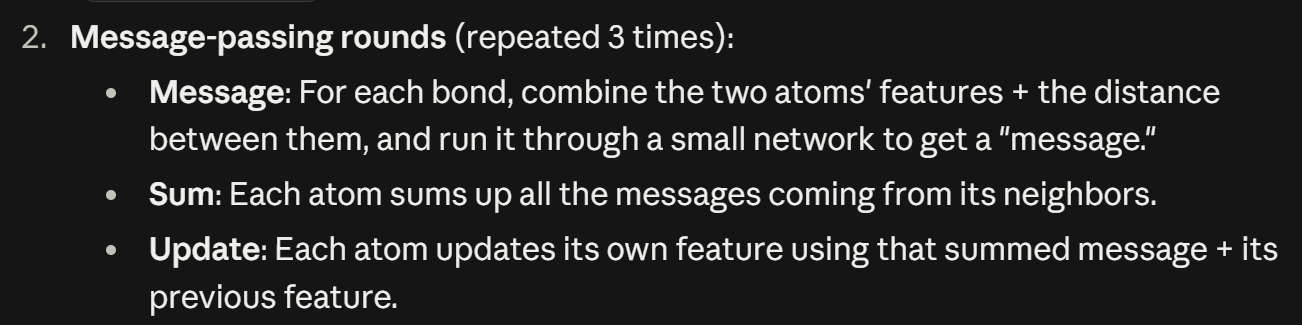

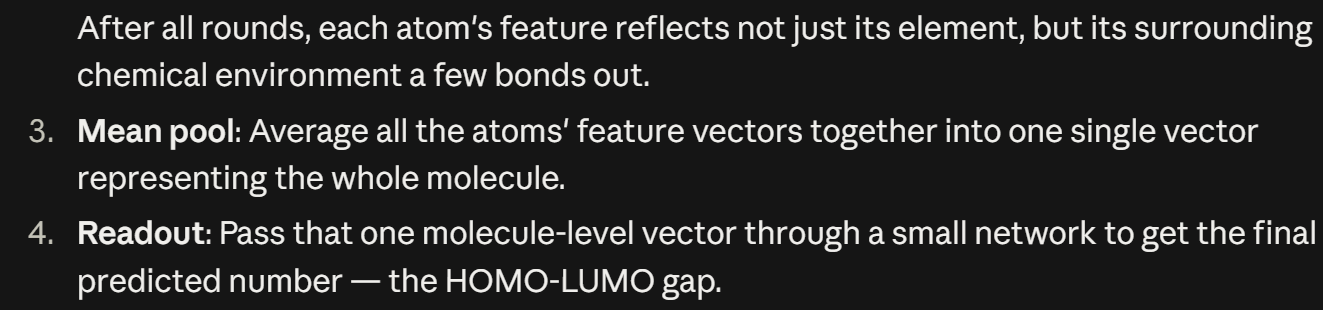

### Permutation invariance check

Creating a function which will run the invariance check on the trained model.

We first start with a function which will check permutation invariance on a **single** molecule. 

In [8]:
def check_permutation_invariance(model, mol, n_trials=3, seed=0):
    model.eval()
    torch.manual_seed(seed)
    all_matched = True

    with torch.no_grad():
        # original ordering - wrap the single molecule as a "batch of 1" so predict_fn (which accepts batch) works unchanged
        # manually feeding one single molecule directly into the model
        original_batch = torch.zeros(mol.z.size(0), dtype=torch.long)  # the batch [0,...,0] = all atoms in this batch belong to molecule 0 
        # for example: mol.z = [6, 8, 1] , mol.edge_index = [[0,1],[1,2]]
        orig_pred = model(mol.pos, mol.z, mol.edge_index, original_batch).item()

        for trial in range(n_trials):
            n_atoms = mol.z.size(0)
            perm = torch.randperm(n_atoms) # a random reordering of atom indices
            # for example: perm = [2, 0, 1]

            # relabel atoms according to the permutation
            shuffled_pos = mol.pos[perm]
            shuffled_z = mol.z[perm] # for example: shuffled_z = [1, 6, 8]

            # remap edge_index to point at the NEW positions of each atom
            inverse_perm = torch.empty_like(perm) 
            inverse_perm[perm] = torch.arange(n_atoms) # inverse_perm = [1, 2, 0]
            shuffled_edge_index = inverse_perm[mol.edge_index] # for example: mol.edge_index = [[1,2],[2,0]]

            # running the model on this relabeled version
            shuffled_batch = torch.zeros(n_atoms, dtype=torch.long)
            shuffled_pred = model(shuffled_pos, shuffled_z, shuffled_edge_index, shuffled_batch).item()

            match = abs(shuffled_pred - orig_pred) < 1e-4
            all_matched = all_matched and match # in order to check all 3 tries have succeeded

        return all_matched # either true or false

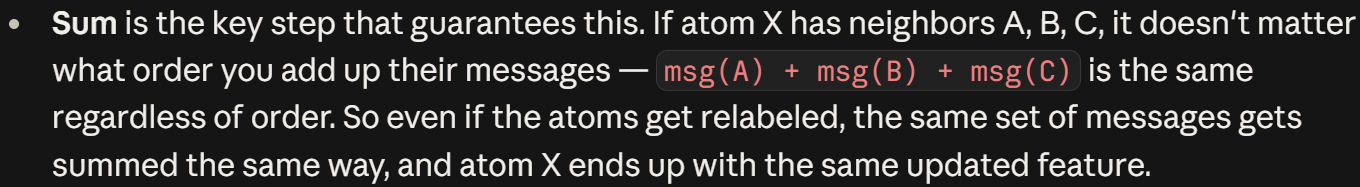

We then create a function which will call the previous function for different molecules in the dataset.

In [9]:
def check_permutation_invariance_multi(model, dataset, indices, n_trials=3, seed=0):
    """Run the permutation-invariance check across several different molecules."""
    results = {}
    for idx in indices:
        mol = dataset[idx]
        results[idx] = check_permutation_invariance(model, mol, n_trials=n_trials, seed=seed)

    n_passed = sum(results.values())
    print(f"Summary: {n_passed}/{len(results)} molecules fully passed the invariance check.")
    return results

Checking 50 different molecules for permutation invariance.

In [ ]:
_ = check_permutation_invariance_multi(gnn_model, test_set, indices=range(0, 5000, 100)) # throwing the return value into a variable and printing what was needed

Summary: 50/50 molecules fully passed the invariance check.


We tested the trained GNN across 50 molecules sampled evenly from the test set, with 3 independent random atom-order shuffles per molecule. All 50 molecules (150/150 shuffles) produced predictions identical to their original-ordering prediction within floating-point tolerance, confirming the model's output does not depend on the arbitrary labeling of atoms.

### Calibrated uncertainty (Ensemble)

We train several independent GNNs on the same data, differing only in their random weight initialization. Since each model starts from a different random point and takes a slightly different path during training, they won't all learn the exact same function. That disagreement is the spread across the ensemble's predictions which becomes the GNN model's uncertainty estimation. 

The final prediction is the average of the ensemble, and the uncertainty is how much the individual models vary around that average.

In [15]:
N_ENSEMBLE = 5
gnn_ensemble = []
ensemble_histories = []

for i in range(N_ENSEMBLE):
    torch.manual_seed(i)  # different seed -> ensures every ensemble member starts with genuinely different random weights
    model_i = MolGNN()
    history_i = train_and_eval(model_i, train_loader, val_loader,
                                predict_fn=gnn_predict_fn,
                                target_index=target_index,
                                name=f"GNN ensemble member {i+1}/{N_ENSEMBLE}",
                                lr=1e-3)
    gnn_ensemble.append(model_i)
    ensemble_histories.append(history_i)

epoch   1 | train MAE: 1.1967 | val MAE: 0.7323 eV
epoch   2 | train MAE: 0.7318 | val MAE: 0.6914 eV
epoch   3 | train MAE: 0.6934 | val MAE: 0.6550 eV
epoch   4 | train MAE: 0.6129 | val MAE: 0.5301 eV
epoch   5 | train MAE: 0.5204 | val MAE: 0.4949 eV
epoch   6 | train MAE: 0.4195 | val MAE: 0.3673 eV
epoch   7 | train MAE: 0.3594 | val MAE: 0.3497 eV
epoch   8 | train MAE: 0.3399 | val MAE: 0.3248 eV
epoch   9 | train MAE: 0.3277 | val MAE: 0.3169 eV
epoch  10 | train MAE: 0.3179 | val MAE: 0.3075 eV

GNN ensemble member 1/5      final val MAE: 0.3075 eV
epoch   1 | train MAE: 1.1972 | val MAE: 0.7323 eV
epoch   2 | train MAE: 0.7184 | val MAE: 0.6784 eV
epoch   3 | train MAE: 0.6565 | val MAE: 0.5843 eV
epoch   4 | train MAE: 0.5720 | val MAE: 0.5126 eV
epoch   5 | train MAE: 0.4875 | val MAE: 0.4517 eV
epoch   6 | train MAE: 0.4245 | val MAE: 0.3862 eV
epoch   7 | train MAE: 0.3866 | val MAE: 0.3716 eV
epoch   8 | train MAE: 0.3576 | val MAE: 0.3612 eV
epoch   9 | train MAE: 0.33

Saving the models

In [17]:
torch.save(model_i.state_dict(), f"gnn_ensemble_member_{i}.pt")

In [18]:
model_i.load_state_dict(torch.load(f"gnn_ensemble_member_{i}.pt"))

<All keys matched successfully>

In [10]:
# Running every ensemble member on one batch 
# yielding per-molecule mean (averaging all predictions of each molecule) and std across the ensemble
def ensemble_predict_batch(ensemble, batch, predict_fn):
    preds = [] # keeping predictions of all models
    for model in ensemble:
        model.eval()
        with torch.no_grad():
            pred = predict_fn(model, batch) # shape: (num_molecules_in_batch,)
        preds.append(pred)
    preds = torch.stack(preds, dim=0) # shape: (N_ENSEMBLE, num_molecules_in_batch)
    mean_pred = preds.mean(dim=0) # shape: (num_molecules_in_batch,)
    std_pred = preds.std(dim=0) # shape: (num_molecules_in_batch,)
    return mean_pred, std_pred # yielding the mean and std of each molecule in the batch

# Running the ensemble over every batch in a loader, collecting per-molecule mean, std, and true target
def ensemble_predict_dataset(ensemble, loader, predict_fn):
    all_means, all_stds, all_targets = [], [], []
    for batch in loader:
        mean_pred, std_pred = ensemble_predict_batch(ensemble, batch, predict_fn)
        target = batch.y[:, target_index]
        all_means.append(mean_pred)
        all_stds.append(std_pred)
        all_targets.append(target)
    return torch.cat(all_means), torch.cat(all_stds), torch.cat(all_targets) # collecting everything into one long tensor covering every molecule in that split (which will be the test set) 

For each test molecule, the 5 independently-initialized GNN ensemble members give 5 separate predictions. For each molecule those 5 predictions define the mean (point estimate) and the std (uncertainty). We treat each prediction as a sample from an approximately Gaussian distribution centered at the mean.

In [68]:
# running this batch-by-batch across the entire test loader
means_gnn, stds_gnn, targets_gnn = ensemble_predict_dataset(gnn_ensemble, test_loader, gnn_predict_fn) 

Calibrated uncertainty via ensemble coverage.

To check whether this uncertainty is calibrated we will run a coverage check: we will compare the empirical coverage against the theoretical coverage: the theoretical coverage is what a perfect Gaussian predicts should fall within mean ± k·σ ($68%$ at $1\sigma$, $95%$ at $2\sigma$, $99.7%$ at $3\sigma$); the empirical coverage is what we actually measured - the real fraction of true test values that landed inside those same intervals. 

If the empirical coverage closely tracks the theoretical coverage at each $\sigma$ level, the model's uncertainty estimates are well-calibrated; a large gap between them (empirical consistently below theoretical) means the model is overconfident, while empirical consistently above theoretical means it's underconfident (reporting wider uncertainty than it needs to).

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Regression calibration: calibration curve + coverage ----------
from scipy.stats import norm
def regression_calibration(y_true, mu, sigma, n_levels=11):
    '''Given predicted Gaussian posteriors N(mu, sigma^2) and true y, return the
    calibration curve (nominal vs observed coverage), the 1-sigma & 2-sigma central
    coverage, and a single calibration-error number (mean |observed - nominal|).'''
    y_true, mu, sigma = map(np.asarray, (y_true, mu, sigma))
    nominal = np.linspace(0.0, 1.0, n_levels)
    observed = np.array([(y_true <= mu + sigma * norm.ppf(q)).mean() if 0 < q < 1 else float(q == 1.0)
                         for q in nominal])
    z = (y_true - mu) / sigma
    cov_1s = float((np.abs(z) <= 1).mean()); cov_2s = float((np.abs(z) <= 2).mean())
    cal_err = float(np.mean(np.abs(observed - nominal)))
    return nominal, observed, cov_1s, cov_2s, cal_err

def plot_regression_calibration(y_true, mu, sigma, title="Regression calibration"):
    nominal, observed, c1, c2, cal_err = regression_calibration(y_true, mu, sigma)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot([0, 1], [0, 1], 'k--', label="perfect calibration")
    ax.plot(nominal, observed, 'o-', label="model")
    ax.set_xlabel("nominal coverage"); ax.set_ylabel("observed coverage")
    ax.set_title(f"{title}\n1σ cov={c1:.2f} (want 0.68), 2σ cov={c2:.2f} (want 0.95)")
    ax.legend(); ax.set_aspect("equal"); plt.tight_layout(); plt.show()
    return c1, c2, cal_err

print("Calibration helpers ready: plot_reliability(...) and plot_regression_calibration(...).")

Calibration helpers ready: plot_reliability(...) and plot_regression_calibration(...).


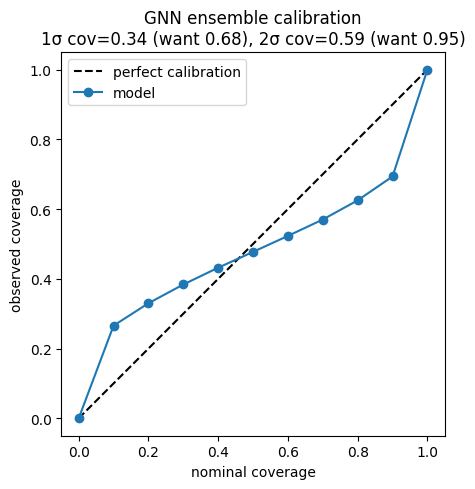

1σ coverage: 0.34 (want 0.68)
2σ coverage: 0.59 (want 0.95)
calibration error: 0.093


In [28]:
c1, c2, cal_err = plot_regression_calibration(
    targets_gnn.numpy(), means_gnn.numpy(), stds_gnn.numpy(),
    title="GNN ensemble calibration"
)

print(f"1σ coverage: {c1:.2f} (want 0.68)")
print(f"2σ coverage: {c2:.2f} (want 0.95)")
print(f"calibration error: {cal_err:.3f}")

Our 5-member ensemble's uncertainty is poorly calibrated: $1\sigma$ coverage is $35%$ (expected ~$68%$) and $2\sigma$ coverage is $61%$ (expected ~$95%$). 

Furthermore, rather than sitting uniformly below the diagonal (which would indicate simple overconfidence), the curve crosses the diagonal: at low nominal coverage (narrow intervals near the predicted mean) the model is underconfident (with more molecules landing very close to their predicted value than a Gaussian would predict) and at high nominal coverage (wide intervals) the model becomes overconfident, with more molecules missing the interval than expected.

This pattern fits with a heavy-tailed error distribution and not a Gaussian distribution - most molecules were predicted accurately, with a minority of large misses the ensemble's spread doesn't anticipate. A likely cause is limited ensemble diversity (or maybe the lack of it), since all members share the same architecture and training data, **differing only in initialization**. A GNN with this much training data is more data-driven than initialization-driven, meaning random seed is a relatively weak source of diversity here.

We therefore should not treat this ensemble's std as a fully trustworthy per-molecule error bar without further recalibration or a more diverse ensemble.

We can try to use bootstrap resampling, which gives each ensemble member a slightly different subset of training molecules, so in principle it can push models toward different local minima and increase disagreement on hard cases, on top of the diversity already provided by different random initializations.

### Calibration with bootsrap

In [13]:
import torch
from torch.utils.data import Subset

n_train = len(train_set)

N_ENSEMBLE = 5
gnn_ensemble_bootstrap = []
ensemble_histories_bootstrap = []

for i in range(N_ENSEMBLE):
    torch.manual_seed(i)

    # bootstrap sample: draw n_train indices WITH replacement from the training set
    boot_indices = torch.randint(0, n_train, (n_train,))
    boot_subset = Subset(train_set, boot_indices.tolist())
    boot_loader = DataLoader(boot_subset, batch_size=256, shuffle=True)

    model_i = MolGNN()
    history_i = train_and_eval(model_i, boot_loader, val_loader,
                                predict_fn=gnn_predict_fn,
                                target_index=target_index,
                                name=f"GNN bootstrap member {i+1}/{N_ENSEMBLE}",
                                lr=1e-3)
    gnn_ensemble_bootstrap.append(model_i)
    ensemble_histories_bootstrap.append(history_i)

epoch   1 | train MAE: 1.1641 | val MAE: 0.7232 eV
epoch   2 | train MAE: 0.7178 | val MAE: 0.6755 eV
epoch   3 | train MAE: 0.6446 | val MAE: 0.5931 eV
epoch   4 | train MAE: 0.5179 | val MAE: 0.4471 eV
epoch   5 | train MAE: 0.4318 | val MAE: 0.4875 eV
epoch   6 | train MAE: 0.4043 | val MAE: 0.4021 eV
epoch   7 | train MAE: 0.3886 | val MAE: 0.3625 eV
epoch   8 | train MAE: 0.3665 | val MAE: 0.3459 eV
epoch   9 | train MAE: 0.3629 | val MAE: 0.3455 eV
epoch  10 | train MAE: 0.3431 | val MAE: 0.3254 eV

GNN bootstrap member 1/5     final val MAE: 0.3254 eV
epoch   1 | train MAE: 1.1425 | val MAE: 0.7256 eV
epoch   2 | train MAE: 0.7090 | val MAE: 0.6645 eV
epoch   3 | train MAE: 0.6417 | val MAE: 0.6108 eV
epoch   4 | train MAE: 0.5771 | val MAE: 0.5983 eV
epoch   5 | train MAE: 0.5287 | val MAE: 0.4863 eV
epoch   6 | train MAE: 0.4510 | val MAE: 0.3825 eV
epoch   7 | train MAE: 0.3568 | val MAE: 0.3390 eV
epoch   8 | train MAE: 0.3334 | val MAE: 0.3542 eV
epoch   9 | train MAE: 0.31

In [16]:
# running this batch-by-batch across the entire test loader
means_gnn_b, stds_gnn_b, targets_gnn_b = ensemble_predict_dataset(gnn_ensemble_bootstrap, test_loader, gnn_predict_fn) 

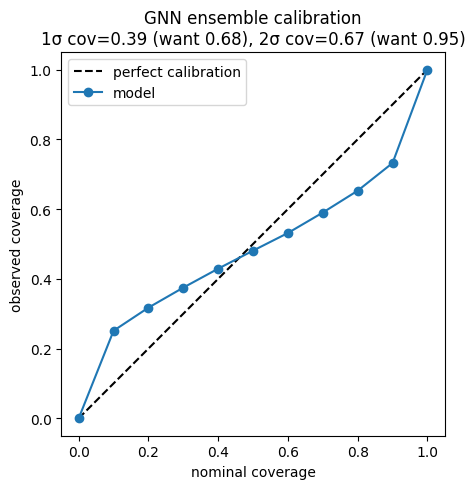

1σ coverage: 0.39 (want 0.68)
2σ coverage: 0.67 (want 0.95)
calibration error: 0.081


In [17]:
cb1, cb2, cal_err_b = plot_regression_calibration(
    targets_gnn_b.numpy(), means_gnn_b.numpy(), stds_gnn_b.numpy(),
    title="GNN ensemble calibration")

print(f"1σ coverage: {cb1:.2f} (want 0.68)")
print(f"2σ coverage: {cb2:.2f} (want 0.95)")
print(f"calibration error: {cal_err_b:.3f}")

We tried two different sources of ensemble diversity (random initialization, bootstrap resampling), and both converged to the same miscalibration. This is likely because our training set is large (~91,000 molecules): a bootstrap resample of this size statistically resembles the full training set closely enough that it adds little diversity beyond what random initialization alone already provides. In other words, with this much data, training is dominated by the data itself rather than by these sources of randomness, so neither method meaningfully diversified the ensemble

### Out-of-distribution flagging

The model might be overconfident on molecules which are far from the training distribution (an unusual ratio of atom types, a shape it's never really seen, more atoms than anything it trained on). It'll still spit out a number and a small uncertainty, because nothing stops it from making a prediction - but in this case, that prediction is closer to a guess, extrapolated from patterns that don't really apply to this case.

On a familiar molecule, all 5 models learned similar patterns and agreed (small std, low uncertainty). On a unfamiliar molecule, the 5 models, never having seen much like it - might extrapolate in 5 different directions, disagree with each other, and produce a large std (high uncertainty). If that happens, the model should correctly flag the unfamiliar molecule as one which shouldn't be trusted too much.

For simplicity, we define a molecule as "far from the training distribution" by how much its atom composition (H/C/N/O/F counts) deviates from the training set's average, standardized by each atom type's typical variation. We then check whether the ensemble's uncertainty (which was computed from the test set) rises for molecules with larger deviations - confirming the model correctly flags unfamiliar molecules as less trustworthy. 

correlation between OOD distance and predicted std: 0.144


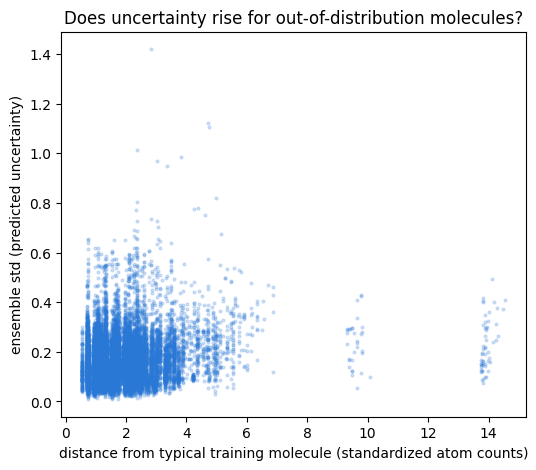

In [ ]:
# on average, molecules might have roughly X carbons, Y hydrogens, etc.
# averaging atom-count profile of the training set (the "typical" molecule)
train_counts = []
for batch in train_loader:
    train_counts.append(atom_count_features(batch))
train_counts = torch.cat(train_counts) # accepts a list of PyTorch tensors (with the exact same shape) and returns a new tensor which contains all the input tensors glued together 
train_mean = train_counts.mean(dim=0) # averages down each column, across all molecules
train_std = train_counts.std(dim=0) + 1e-6 # how spread out are these values, avoid divide-by-zero

# for each test molecule, a standardized distance from that "typical" profile
test_counts = []
for batch in test_loader:
    test_counts.append(atom_count_features(batch))
test_counts = torch.cat(test_counts)
ood_distance = ((test_counts - train_mean) / train_std).norm(dim=1) # one number per test molecule

# correlation: does the ensemble's std rise for molecules far from the training distribution?
corr = torch.corrcoef(torch.stack([ood_distance, stds_gnn]))[0, 1].item() # takes 2 (n_test,) tensors and stacks them into (2,n_test). 'corrcoef' -> each row of that 2D tensor is one "variable" (so 2 variables here: OOD distance and std) and each column as one observation of both variables together. It computes the full correlation matrix between all pairs of variables, returning a (2, 2) tensor
print(f"correlation between OOD distance and predicted std: {corr:.3f}")

plt.figure(figsize=(6, 5))
plt.scatter(ood_distance.numpy(), stds_gnn.numpy(), s=4, alpha=0.2, color="#2a78d6")
plt.xlabel("distance from typical training molecule (standardized atom counts)")
plt.ylabel("ensemble std (predicted uncertainty)")
plt.title("Does uncertainty rise for out-of-distribution molecules?")
plt.show()

This confirms, in visual way, what the correlation number have stemed from: this ensemble's uncertainty does not track how far a molecule is from the training distribution (in the way we defined distance at least). This is related to the general miscalibration we found earlier.

The ensemble is miscalibrated and two different diversity strategies (seed, bootstrap) failed to fix it (the dataset is too large, data-driven for either to matter), and now we find this - the uncertainty also doesn't track distributional unusualness correctly. All three findings point the same direction: this ensemble's std isn't a trustworthy signal, in more than one sense.

### Test set MAE

In [83]:
gnn_test_mae = torch.abs(targets_gnn - means_gnn).mean().item()
print(f"GNN ensemble test MAE: {gnn_test_mae:.4f} eV")

GNN ensemble test MAE: 0.2963 eV


---
## Model 3 - Set Transformer

Instead of message-passing along explicit bonds (edges) like the GNN, it treats a molecule as an unordered set of atoms and uses self-attention: every atom "looks at" every other atom directly, weighting how much attention to pay to each based on learned features (like interatomic distance). That's what makes it fundamentally different from the GNN - geometry doesn't take place here, but interatomic distance.

In [ ]:
# ---------- Required second model for Project B: a permutation-invariant atom TRANSFORMER ----------
def rbf_expand(D, n_rbf=16, cutoff=4.0):
    """Radial-basis expansion of pairwise distances -> smooth geometry features for the attention bias."""
    centers = torch.linspace(0, cutoff, n_rbf)
    width = centers[1] - centers[0]
    return torch.exp(-((D.unsqueeze(-1) - centers) / width) ** 2)        # (..., n_rbf)

class AtomTransformer(nn.Module):
    """Treats a molecule as a SET of atoms. Self-attention with NO positional encoding (atoms are
    unordered -> permutation-equivariant), a distance-based attention bias (rotation/translation-
    invariant), then pooling over atoms -> a permutation-INVARIANT molecule-level prediction.
    NOTE: use SUM pooling for an EXTENSIVE property (a sum over the molecule); mean pooling will underperform badly on such targets -- a physics-prior lesson worth demonstrating."""
    def __init__(self, n_types, dim=64, heads=4, layers=3, n_rbf=16, pool="sum"):
        super().__init__()
        self.embed = nn.Embedding(n_types, dim); self.heads = heads; self.dim = dim; self.pool = pool
        self.ln1 = nn.ModuleList([nn.LayerNorm(dim) for _ in range(layers)])
        self.ln2 = nn.ModuleList([nn.LayerNorm(dim) for _ in range(layers)])
        self.qkv = nn.ModuleList([nn.Linear(dim, dim * 3) for _ in range(layers)])
        self.proj = nn.ModuleList([nn.Linear(dim, dim) for _ in range(layers)])
        self.ff = nn.ModuleList([nn.Sequential(nn.Linear(dim, dim * 2), nn.SiLU(), nn.Linear(dim * 2, dim)) for _ in range(layers)])
        self.dist_bias = nn.ModuleList([nn.Linear(n_rbf, heads) for _ in range(layers)])   # RBF(dist) -> per-head bias
        self.readout = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, 1))
    def forward(self, pos, z, mask=None):
        # single molecule: pos (N,3), z (N,)   [batch by stacking equal-N molecules: pos (B,N,3), z (B,N)]
        single = (z.dim() == 1)
        if single: pos, z = pos.unsqueeze(0), z.unsqueeze(0)
        B, N = z.shape
        h = self.embed(z); R = rbf_expand(torch.cdist(pos, pos))

        if mask is None:
            mask = torch.ones(B, N, dtype=torch.bool, device=z.device)

        for i in range(len(self.qkv)):
            x = self.ln1[i](x if False else self.ln1[i](h) if False else h)  # placeholder
            x = self.ln1[i](h); q, k, v = self.qkv[i](x).chunk(3, -1)
            q = q.view(B, N, self.heads, -1); k = k.view(B, N, self.heads, -1); v = v.view(B, N, self.heads, -1)
            att = torch.einsum('bihd,bjhd->bijh', q, k) / np.sqrt(self.dim // self.heads) + self.dist_bias[i](R) # [batch_size, target_nodes, source_nodes]
            att = att.masked_fill(~mask[:, None, :, None], float('-inf')) # padded atoms (marked here as 'True') get -inf score, so that later softmax gives them ~0 weight
            att = torch.softmax(att, 2) # Apply softmax along the 3rd dimension (index 2)
            # This ensures that for each target node, the sum of attention weights coming from all source nodes equals 1.0
            # real atoms end up giving essentially zero attention weight to fake atoms
            out = torch.einsum('bijh,bjhd->bihd', att, v).reshape(B, N, self.dim)
            h = h + self.proj[i](out); h = h + self.ff[i](self.ln2[i](h))

        h = h * mask.unsqueeze(-1) # zero out padded atoms' features before pooling
        if self.pool == "sum":
            pooled = h.sum(1)
        else:
            pooled = h.sum(1) / mask.sum(1, keepdim=True).clamp(min=1) # mean over REAL atoms only, not N_max
        out = self.readout(pooled)
        return out.squeeze(0) if single else out

print("AtomTransformer ready (permutation-invariant set transformer; use pool='sum' for extensive targets).")

AtomTransformer ready (permutation-invariant set transformer; use pool='sum' for extensive targets).


As mentioned in the helper code, given forward expects pos shaped (B, N, 3) and z shaped (B, N) - every molecule in a batch must have the same atom count N. Real molecules don't. The fix is padding: for each batch, we will find the largest molecule (N_max), pad every smaller molecule up to that size with dummy "filler" atoms, and add a mask so the model knows to ignore those filler atoms in attention (otherwise it would treat empty padding as if it were real atoms and let them influence the real ones).

In [ ]:
def batch_to_dense(batch, target_index):
    """Convert a PyG batch (variable-size graphs, concatenated) into the AtomTransformer's
    expected dense (B, N, ...) shape, padded to the largest molecule in this batch."""
    device = batch.z.device # all atoms from all molecules in the batch laid end-to-end in one long list, with no gaps between molecules
    num_graphs = batch.num_graphs # how many separate molecules got concatenated into this one batch object
    counts = torch.bincount(batch.batch, minlength=num_graphs) # number of atoms per molecule in this batch
    N_max = counts.max().item() # the single largest atom count in this batch

    # rows - number of molecules in batch, columns = zeros size of N_max
    pos_dense = torch.zeros(num_graphs, N_max, 3, device=device)
    z_dense = torch.zeros(num_graphs, N_max, dtype=torch.long, device=device)
    mask = torch.zeros(num_graphs, N_max, dtype=torch.bool, device=device)  # rows = n_graphs, each N_max long

    ptr = 0
    for i in range(num_graphs): # for molecule i in batch
        n = counts[i].item() # returns amount of atoms this molecule has
        pos_dense[i, :n] = batch.pos[ptr:ptr+n] # slice out n atoms and write them into the first n slots of row i in our padded tensors
        z_dense[i, :n] = batch.z[ptr:ptr+n]
        mask[i, :n] = True # marking the atoms in the i'th row (molecule) as true
        ptr += n # move on to the next molecule

    target = batch.y[:, target_index]
    return pos_dense, z_dense, mask, target

Like before, we need a prediction function for the training function. This function takes a batch from the loader and returns predictions.

In [48]:
def transformer_predict_fn(model, batch):
    pos, z, mask, target = batch_to_dense(batch, target_index) # conversion to the padded shape the transformer takes
    pred = model(pos, z, mask=mask)
    return pred.squeeze(-1)

In [39]:
transformer_model = AtomTransformer(n_types=10, pool="mean")

In [40]:
transformer_history = train_and_eval(transformer_model, train_loader, val_loader,
                                      predict_fn=transformer_predict_fn,
                                      target_index=target_index,
                                      name="Transformer (self-attention)",
                                      lr=1e-3)

epoch   1 | train MAE: 0.9424 | val MAE: 0.6769 eV
epoch   2 | train MAE: 0.5927 | val MAE: 0.5015 eV
epoch   3 | train MAE: 0.4793 | val MAE: 0.4541 eV
epoch   4 | train MAE: 0.3956 | val MAE: 0.3631 eV
epoch   5 | train MAE: 0.3515 | val MAE: 0.3300 eV
epoch   6 | train MAE: 0.3292 | val MAE: 0.3184 eV
epoch   7 | train MAE: 0.3105 | val MAE: 0.3013 eV
epoch   8 | train MAE: 0.2882 | val MAE: 0.3070 eV
epoch   9 | train MAE: 0.2780 | val MAE: 0.3086 eV
epoch  10 | train MAE: 0.2705 | val MAE: 0.2467 eV

Transformer (self-attention) final val MAE: 0.2467 eV


In [42]:
torch.save(transformer_model.state_dict(), "transformer_model.pt")

### Permutation invariance check

We will adapt the function we created earlier for the GNN model. 

In [ ]:
def check_permutation_invariance_transformer(model, mol, n_trials=3, seed=0):
    model.eval()
    torch.manual_seed(seed) # fixating the random seed so the shuffles are reproducible run to run
    all_matched = True

    with torch.no_grad():
        n_atoms = mol.z.size(0)
        orig_pred = model(mol.pos, mol.z).item() 

        for trial in range(n_trials):
            perm = torch.randperm(n_atoms)
            shuffled_pos = mol.pos[perm]
            shuffled_z = mol.z[perm]
            shuffled_pred = model(shuffled_pos, shuffled_z).item()

            match = abs(shuffled_pred - orig_pred) < 1e-4
            all_matched = all_matched and match

        return all_matched

def check_permutation_invariance_transformer_multi(model, dataset, indices, n_trials=3, seed=0):
    """Run the permutation-invariance check across several different molecules."""
    results = {}
    for idx in indices:
        mol = dataset[idx]
        results[idx] = check_permutation_invariance_transformer(model, mol, n_trials=n_trials, seed=seed)

    n_passed = sum(results.values())
    print(f"Summary: {n_passed}/{len(results)} molecules fully passed the invariance check.")
    return results

In [50]:
_ = check_permutation_invariance_transformer_multi(transformer_model, test_set, indices=range(0, 5000, 100))

Summary: 50/50 molecules fully passed the invariance check.


### Calibrated uncertainty (Ensemble)

In [55]:
# N_ENSEMBLE = 5
# transformer_ensemble = []
# transformer_ensemble_histories = []

# for i in range(N_ENSEMBLE):
#     torch.manual_seed(i)
#     model_i = AtomTransformer(n_types=10, pool="mean")
#     history_i = train_and_eval(model_i, train_loader, val_loader,
#                                 predict_fn=transformer_predict_fn,
#                                 target_index=target_index,
#                                 name=f"Transformer ensemble member {i+1}/{N_ENSEMBLE}",
#                                 lr=1e-2)
#     transformer_ensemble.append(model_i)
#     transformer_ensemble_histories.append(history_i)

I used the GPU in google collab after a failed night of training.

I then extracted the trained models to this file to use.

In [60]:
import zipfile
with zipfile.ZipFile("transformer_ensemble_weights.zip", "r") as z:
    z.extractall("transformer_ensemble_weights")

In [61]:
transformer_ensemble = []
for i in range(5):
    model_i = AtomTransformer(n_types=10, pool="mean")
    model_i.load_state_dict(torch.load(f"transformer_ensemble_weights/transformer_{i}.pt", map_location=torch.device("cpu")))
    model_i.eval()
    transformer_ensemble.append(model_i)

In [62]:
import os
print(os.listdir("transformer_ensemble_weights"))

['transformer_0.pt', 'transformer_1.pt', 'transformer_2.pt', 'transformer_3.pt', 'transformer_4.pt']


In [63]:
means_t, stds_t, targets_t = ensemble_predict_dataset(transformer_ensemble, test_loader, transformer_predict_fn)

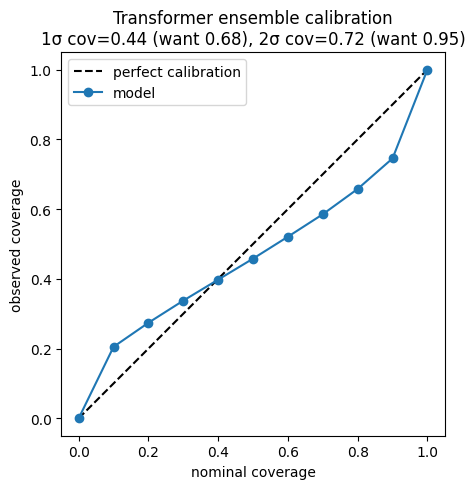

In [64]:
c1_t, c2_t, cal_err_t = plot_regression_calibration(targets_t.numpy(), means_t.numpy(), stds_t.numpy(),
                                                      title="Transformer ensemble calibration")

### Out-of-distribution flagging

Transformer — correlation between OOD distance and predicted std: 0.224


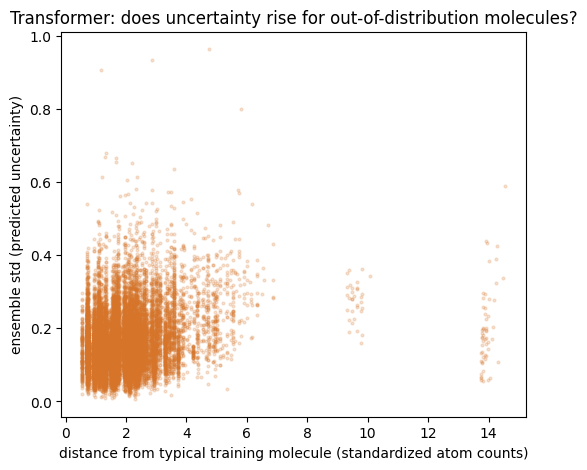

In [71]:
corr_t = torch.corrcoef(torch.stack([ood_distance, stds_t]))[0, 1].item()
print(f"Transformer - correlation between OOD distance and predicted std: {corr_t:.3f}")

plt.figure(figsize=(6, 5))
plt.scatter(ood_distance.numpy(), stds_t.numpy(), s=4, alpha=0.2, color="#d6752a")
plt.xlabel("distance from typical training molecule (standardized atom counts)")
plt.ylabel("ensemble std (predicted uncertainty)")
plt.title("Transformer: does uncertainty rise for out-of-distribution molecules?")
plt.show()

### Test-set MAE

In [85]:
transformer_test_mae = torch.abs(targets_t - means_t).mean().item()
print(f"Transformer ensemble test MAE: {transformer_test_mae:.4f} eV")

Transformer ensemble test MAE: 0.2223 eV


## Comparison of the models

### MAE evaluation on the test set


In [90]:
print(f"Baseline test MAE:    {baseline_test_mae:.4f}")
print(f"GNN test MAE:         {gnn_test_mae:.4f}")
print(f"Transformer test MAE: {transformer_test_mae:.4f}")

Baseline test MAE:    0.8390
GNN test MAE:         0.2963
Transformer test MAE: 0.2223


All three models were evaluated on the same test set, using the ensemble mean as the point prediction for the GNN and transformer. The baseline (atom counts only) reaches an MAE of $0.839$ eV. The GNN shows significant improvement as the model can see the molecule's actual 3D geometry: $0.296$ eV. The transformer shows even better result as its MAE reaches $0.222$ eV. This makes sense - HOMO-LUMO gap depends heavily on how a molecule is shaped in space, not just which atoms it contains, so composition alone (the baseline) is a weak predictor. 

The baseline's input is only `[H count, C count, N count, O count, F count]`. That means **any two molecules with the same atom counts look completely identical to the model** - even if they're chemically very different molecules (isomers) and therefore have genuinely different HOMO-LUMO gaps in reality (two different targets, which the network is unable to satisfy simultaneously, thus taking the average). No amount of training can fix this, because the information needed to predict correctly (the actual structure) was thrown away before the model ever saw the data.

Between the two geometry-aware models, the transformer is noticeably more accurate than the GNN. A likely reason is that the HOMO-LUMO gap depends on the molecule's overall electronic structure, which can be spread across atoms that aren't directly bonded. Although the GNN doesn't need to learn the structure the way the transformer has to, it can only pass information along actual bonds, so it has to relay information step by step to connect distant atoms. Meanwhile the transformer lets every atom attend to every other atom directly, which may make it better suited to a property like this one.

### Uncertainty and error correlation

Earlier, the coverage check showed the transformer's uncertainty was slightly better calibrated than the GNN's (1σ coverage 0.44 vs 0.35, 2σ coverage 0.72 vs 0.61). 

One possible reason is that the uncertanty of the transformer is bigger.

In [93]:
print(f"GNN ensemble - mean std: {stds_gnn.mean().item():.4f}, median std: {stds_gnn.median().item():.4f}")
print(f"Transformer - mean std: {stds_t.mean().item():.4f}, median std: {stds_t.median().item():.4f}")

GNN ensemble - mean std: 0.1624, median std: 0.1460
Transformer - mean std: 0.1578, median std: 0.1438


Since both models have almost the same average uncertainty magnitude (~0.16), the difference isn't about how big the uncertainty is.

Another possible explanation is how well-targeted it is, which we can check by correlating each model's prediction error with its predicted uncertainty.

In [ ]:
abs_error_gnn = torch.abs(targets_gnn - means_gnn) # how far off the ensemble's mean prediction was from the true HOMO-LUMO gap.
abs_error_t = torch.abs(targets_t - means_t)

corr_gnn = torch.corrcoef(torch.stack([abs_error_gnn, stds_gnn]))[0, 1].item() # pulling up off diagonal numbers from the distribution
corr_t = torch.corrcoef(torch.stack([abs_error_t, stds_t]))[0, 1].item()

print(f"GNN: correlation between |error| and predicted std: {corr_gnn:.3f}")
print(f"Transformer: correlation between |error| and predicted std: {corr_t:.3f}")

GNN: correlation between |error| and predicted std: 0.159
Transformer: correlation between |error| and predicted std: 0.233


This shows the transformer tracks its own mistakes more consistently (0.233) than the GNN does (0.159), which explains why its calibration was better: it's not just guessing a wider or narrower number, it's assigning uncertainty to the right molecules more often.

### Flagging out of distribution

The GNN failed did worse on flagging as well as scored near-zero correlation, while the transformer did better on both (0.233 error-correlation, 0.224 OOD-correlation). The OOD is another angle confirming the same conclusion: the transformer's uncertainty is more informative than the GNN's, not just in one sense but across two different, independent ways of checking whether uncertainty "means something."

### Training costs

Using the same learning rate and epoch count, the transformer took significantly longer to train than the GNN. After a very long attempt which started at night and (has not) ended in the morning, I read the article: "Attention Is All You Need" (Vaswani et al., 2017) which was linked at the lecture which offered an explanation: the transformer's self-attention computes interactions between every pair of atoms, giving it O(N²) computational complexity per layer, where N is the number of atoms in a molecule.

This comes down to how each model processes a molecule: the GNN only passes messages between atoms that are actually bonded, so the amount of computation per molecule stays small and scales with the number of bonds. The transformer, on the other hand, uses self-attention between **every pair of atoms**, so the computation grows quadratically with the number of atoms in the molecule. Across ~91,000 training molecules and a 5-member ensemble, this difference adds up fast.

Given that the transformer ensemble was so slow on CPU ,I had to move it to Google Colab and train it there, using a GPU instead. That has shortened the training time significantly. The GNN ensemble, by contrast, trained fully on CPU without issue. So the transformer's better accuracy and uncertainty calibration came at a real compute cost - it's a heavier model to train, not just a better one.

### Each architecture's strengths mirror the other model weaknesse

GNN:
Its advantage is structure. Message passing only happens along actual bonds and the architecture is handed a strong physical prior for free - it doesn't need to learn which atoms are chemically relevant to each other, bonding already tells it. This should make it comparatively efficient at picking up on properties that depend mostly on bonding (what atom is next to what).

First, the disadvantage of GNN is that atoms can only "talk" to atoms that are directly bonded to each other. If two atoms matter to each other in some sense but aren't bonded, the GNN can only connect them indirectly, by passing a message step by step through everything in between. That makes it harder for the GNN to pick up on effects which depend on the molecule as a whole, rather than just on what's directly next to what (like the HOMO LUMO Gap). Second, knowing when it doesn't know. The ensemble uncertainty barely correlates with actual error (0.159) or with how unusual a molecule is (0.144, near-zero) - meaning the GNN is bad at flagging its own uncertain predictions, even though its raw accuracy is reasonable.

Transformer:
The transformer upcoming is exactly the GNN's weak spot, which is non-local relationships. Every atom attends directly to every other atom in a single layer, **regardless of bonding**, so it doesn't need multiple hops to relate distant parts of a molecule. This likely explains its better raw accuracy (MAE 0.2223 vs. 0.2963) on an intensive, delocalized property like HOMO-LUMO gap. It's also better at recognizing its own uncertain cases, higher error-correlation (0.233) and OOD-correlation (0.224) than the GNN.

On the other hand, the training cost is much larger. With no structural prior telling it which atoms matter to each other, it has to learn that relevance from data via full pairwise attention, and that costs O(N²) computation per molecule, which is why it needed a GPU (Colab) while the GNN trained fine on CPU.

---
## Hyperparameters

- Baseline MLP: `hidden=16`, only sees atom counts, no graph - kept deliberately weak so it shows what structure actually adds.
- GNN: embedding `32`, hidden `64`, 3 message-passing rounds - enough rounds for info to reach across a small molecule. Edge feature = distance (invariant to rotation/translation). Mean pooling since the gap is an intensive (per-molecule-average) property, not a sum over atoms.
- Transformer: `dim=64`, 4 heads, 3 layers - standard small-transformer sizing. 16 distance basis functions to turn raw distances into smooth features for attention. Mean pooling for the same intensive-property reason as the GNN.
- Training (all models): Adam, `lr=1e-3` (standard safe default), 10 epochs - enough for these small models to converge without excessive runtime, batch `256`. Loss = MAE directly, since that's also the evaluation metric.

---
## Self assessment


Both geometry-aware models learned something real: seeing a molecule's actual 3D structure, not just its atom composition, is what mostly determines the HOMO-LUMO gap (baseline MAE 0.839 eV vs. 0.296 for the GNN and 0.222 for the transformer). The transformer's advantage over the GNN likely comes from its ability to relate **any** two atoms directly, which matters for a property that depends on the structure spread across the whole molecule, **not just local bonds**.

Where they fail is uncertainty, not accuracy. Neither ensemble is well-calibrated (1σ/2σ coverage well below the 0.68/0.95 targets for both models), and this didn't improve with more ensemble diversity - bootstrap resampling gave identical results to seed-only, likely because the training set is large enough that individual models converge to similar solutions regardless. The GNN's predicted uncertainty barely tracks anything real: it has almost no correlation with actual error (0.159) or with how unusual a molecule is (0.144). The transformer is better on both (0.233, 0.224), but still far from reliable.

Overall, I'd trust the actual number each model predicts (its point prediction), especially the transformer's, for molecules that look similar to the ones in the training data. But I would not blindly trust the uncertainty number each model gives - both models act more confident than they should be, and the GNN especially doesn't give a useful signal for which predictions are more likely to be wrong.
The coverage numbers show the uncertainty is miscalibrated, and the correlation numbers show it also isn't well-targeted at the right molecules.